# CNN 1D — Cảnh báo sớm SpO2 < 88% (CPU, Keras/TensorFlow)

**Mục tiêu:** từ 60 phút gần nhất của 4 kênh (`spo2_mean`, `spo2_min`, `spo2_valid`, `pulse_mean`), dự đoán 30 phút tới có đợt SpO2 < 88% kéo dài ≥ 3 phút hay không.

**Quy tắc làm việc**
- Chia theo bệnh nhân (đã làm ở `data_splitting`). Val dùng để dừng sớm, chọn model, chọn ngưỡng. **Test chỉ mở một lần ở Mục 7.**
- Chỉ số quyết định: **AUPRC trên val** (mốc ngẫu nhiên ≈ 0,012).
- **Resume:** mất kết nối hoặc ngắt kernel → chạy lại notebook từ đầu, tự tiếp tục từ epoch cuối đã lưu.
- Thử cấu hình mới: đổi `RUN_DIR`. Train lại từ đầu: xóa thư mục `RUN_DIR`. **Không đổi `CFG` giữa chừng khi đang resume.**

**Mục lục:** 1 Cấu hình · 2 Dữ liệu · 3 Mô hình · 4 Huấn luyện · 5 Đọc đường cong · 6 Chấm điểm val · 7 Test (một lần) · 8 Xuất model

## 1. Cấu hình

### 1.1 Thư viện và siêu tham số

In [1]:
import os, json, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score, roc_auc_score

CFG = dict(
    DATA_DIR="../data/data/dataset_thr88",
    RUN_DIR="runs/cnn_thr88_v1",    
    SEED=42, BATCH=512, MAX_EPOCHS=40, PATIENCE=6, LR=1e-3,
    POS_WEIGHT=1.0,                  # 1.0 = không đánh trọng số;
    FILTERS=(16, 32, 32), KERNEL=5, DROPOUT=0.2,
)
RUN = CFG["RUN_DIR"]; os.makedirs(RUN, exist_ok=True)
P = lambda f: f"{RUN}/{f}"
sig = lambda z: 1 / (1 + np.exp(-z))
keras.utils.set_random_seed(CFG["SEED"])
print("TensorFlow", tf.__version__, "| số nhân CPU:", os.cpu_count(), "| GPU:", tf.config.list_physical_devices("GPU"))

d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow 2.21.0 | số nhân CPU: 12 | GPU: []


## 2. Dữ liệu

### 2.1 Nạp và chuẩn hóa
- Chuẩn hóa bằng `mu`, `sd` **chỉ tính trên train**, lưu vào `norm.npz` (ESP32 phải dùng đúng hai vector này).
- Deep learning không nhận NaN: NaN → 0 (tức mức trung bình), kèm 2 kênh **mask** (1 = thiếu) cho `spo2_mean` và `pulse_mean`. Đầu vào cuối: `(N, 60, 6)`.

In [2]:
def load(k):
    z = np.load(f'{CFG["DATA_DIR"]}/{k}.npz'); return z["X"], z["y"].astype("float32")
Xtr_raw, ytr = load("train"); Xva_raw, yva = load("val"); Xte_raw, yte = load("test")

if os.path.exists(P("norm.npz")): mu, sd = (np.load(P("norm.npz"))[k] for k in ("mu", "sd"))
else:
    mu, sd = np.nanmean(Xtr_raw, (0, 1)), np.nanstd(Xtr_raw, (0, 1)) + 1e-6
    np.savez(P("norm.npz"), mu=mu, sd=sd)

def prep(X):
    mask = np.isnan(X[:, :, [0, 3]]).astype("float32")
    return np.concatenate([np.nan_to_num((X - mu) / sd, nan=0.0).astype("float32"), mask], axis=2)
Xtr, Xva, Xte = prep(Xtr_raw), prep(Xva_raw), prep(Xte_raw)
del Xtr_raw, Xva_raw, Xte_raw

print(f"train {Xtr.shape} dương {int(ytr.sum())} | val {Xva.shape} dương {int(yva.sum())} | test {Xte.shape}")
print(f"Tỷ lệ dương (mốc AUPRC ngẫu nhiên): train {ytr.mean():.4f} | val {yva.mean():.4f}")
assert not np.isnan(Xtr).any() and not np.isnan(Xva).any()

train (340195, 60, 6) dương 4205 | val (70513, 60, 6) dương 868 | test (71600, 60, 6)
Tỷ lệ dương (mốc AUPRC ngẫu nhiên): train 0.0124 | val 0.0123


## 3. Mô hình

### 3.1 Kiến trúc
Conv1D(16, k=5) → MaxPool → Conv1D(32, k=5) → MaxPool → Conv1D(32, k=3) → GlobalAveragePooling → Dropout → Dense(1).
- Khoảng 6.200 tham số, đủ nhỏ để chạy trên ESP32.
- Đầu ra là **logit** (chưa sigmoid). Lý do: TFLite INT8 làm tròn sigmoid theo bước 1/256 ≈ 0,004, quá thô so với ngưỡng 0,03–0,06. Sigmoid áp dụng ở ngoài mô hình.
- Loss: `BinaryCrossentropy(from_logits=True)`. AUPRC/AUROC được tính chính xác bằng sklearn mỗi epoch (Mục 4), vì metric AUC của Keras chỉ có 200 ngưỡng chia đều, quá thô khi xác suất đa số nhỏ hơn 0,2.

In [3]:
def build_model():
    L = keras.layers
    inp = keras.Input((60, 6)); x = inp
    for i, f in enumerate(CFG["FILTERS"]):
        x = L.Conv1D(f, CFG["KERNEL"] if i < 2 else 3, padding="same", activation="relu")(x)
        if i < 2: x = L.MaxPooling1D(2)(x)
    x = L.Dropout(CFG["DROPOUT"])(L.GlobalAveragePooling1D()(x))
    m = keras.Model(inp, L.Dense(1)(x), name="cnn1d")
    m.compile(keras.optimizers.Adam(CFG["LR"]), keras.losses.BinaryCrossentropy(from_logits=True))
    return m

build_model().summary()

Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 60, 16)         │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 30, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 30, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 15, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,225 (24.32 KB)

 Trainable params: 6,225 (24.32 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Huấn luyện có lưu trạng thái

### 4.1 Callback quản lý run
Sau **mỗi epoch** callback này:
1. Tính AUPRC/AUROC chính xác trên val và AUPRC trên một tập con train (cùng chế độ eval để so sánh được).
2. Lưu `last.keras` (trọng số + trạng thái optimizer) và `state.json` (epoch, tốt nhất, bộ đếm kiên nhẫn, toàn bộ lịch sử). Ghi qua file tạm rồi đổi tên nên không bị hỏng nếu ngắt giữa lúc ghi.
3. Lưu `best.keras` khi `val_auprc` tăng.
4. In một dòng của bảng, kèm thanh tiến độ tổng (đã chạy/ETA tối đa) và thanh tiến độ trong epoch.

**Cách đọc bảng:** `loss`/`val_loss` là BCE; `auprc` (train, tập con) và `val_auprc` (val) cùng đo bằng sklearn; `gap = auprc − val_auprc`.
- `loss` giảm mà `val_loss` tăng nhiều epoch liền → nghi **overfit** (callback gắn cảnh báo).
- Cả hai cùng cao, gần như phẳng, `val_auprc` sát mốc ngẫu nhiên → **underfit** hoặc tín hiệu yếu.
- `gap` tăng đều → bắt đầu thuộc lòng train.
- Val chỉ có khoảng 54 bệnh nhân dương, nên `val_auprc` giữa các epoch dao động là bình thường; nhìn **xu hướng** nhiều epoch, đừng kết luận từ một epoch.
- `ETA` là cận trên vì early stopping có thể dừng sớm hơn.

In [4]:
class RunManager(keras.callbacks.Callback):
    def __init__(self, st, Xs, ys):
        super().__init__(); self.st, self.Xs, self.ys = st, Xs, ys
    def _save(self, path):
        tmp = path + ".tmp.keras"; self.model.save(tmp); os.replace(tmp, path)
    def _prob(self, X): return sig(self.model.predict(X, batch_size=4096, verbose=0).ravel())
    def on_train_begin(self, logs=None):
        E = CFG["MAX_EPOCHS"]
        self.outer = tqdm(total=E, initial=self.st["epoch"], desc="Tổng tiến độ (tối đa)", unit="epoch", position=0)
        self.outer.write(f"{'Ep':>3} | {'loss':>7} {'val_loss':>8} | {'auprc':>6} {'val_auprc':>9} {'val_auroc':>9} | {'gap':>6} | {'giây':>5} | ghi chú")
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()
        self.inner = tqdm(total=self.params["steps"], desc=f"Epoch {epoch+1}/{CFG['MAX_EPOCHS']}", leave=False, position=1)
    def on_train_batch_end(self, batch, logs=None):
        self.inner.update(1)
        if batch % 20 == 0: self.inner.set_postfix(loss=f"{logs['loss']:.4f}")
    def on_epoch_end(self, epoch, logs=None):
        self.inner.close(); st = self.st
        pv, ps = self._prob(Xva), self._prob(self.Xs)
        r = dict(epoch=epoch + 1, loss=logs["loss"], val_loss=logs["val_loss"],
                 auprc=average_precision_score(self.ys, ps), val_auprc=average_precision_score(yva, pv),
                 val_auroc=roc_auc_score(yva, pv), sec=time.time() - self.t0)
        r["gap"] = r["auprc"] - r["val_auprc"]; H = st["history"]; H.append(r); note = []
        if r["val_auprc"] > st["best"]:
            st["best"], st["best_epoch"], st["wait"] = r["val_auprc"], r["epoch"], 0
            self._save(P("best.keras")); note.append("★ tốt nhất")
        else: st["wait"] += 1
        if len(H) >= 3 and H[-1]["val_loss"] > H[-2]["val_loss"] > H[-3]["val_loss"] and H[-1]["loss"] < H[-3]["loss"]:
            note.append("⚠ val_loss tăng 2 epoch liền (nghi overfit)")
        st["epoch"] = r["epoch"]; st["done"] = st["wait"] >= CFG["PATIENCE"] or r["epoch"] >= CFG["MAX_EPOCHS"]
        self._save(P("last.keras"))
        json.dump(st, open(P("state.json.tmp"), "w")); os.replace(P("state.json.tmp"), P("state.json"))
        self.outer.update(1)
        self.outer.write(f"{r['epoch']:>3} | {r['loss']:7.4f} {r['val_loss']:8.4f} | {r['auprc']:6.3f} {r['val_auprc']:9.3f} "
                         f"{r['val_auroc']:9.3f} | {r['gap']:6.3f} | {r['sec']:5.0f} | {' '.join(note)}")
        if st["done"]:
            self.model.stop_training = True
            self.outer.write("■ Dừng: " + ("hết kiên nhẫn (early stopping)" if st["wait"] >= CFG["PATIENCE"] else "đủ số epoch tối đa"))
    def on_train_end(self, logs=None): self.outer.close()

### 4.2 Chạy huấn luyện (tự resume)
- Lần đầu: tạo model mới. Nếu thấy `last.keras` và `state.json` thì **nạp lại và tiếp tục** từ epoch cuối đã lưu.
- Muốn dừng tay: nút Interrupt của notebook. Epoch đang dở sẽ làm lại, các epoch đã xong không mất.
- Run đã `done` thì bỏ qua.

In [5]:
if os.path.exists(P("state.json")) and os.path.exists(P("last.keras")):
    st = json.load(open(P("state.json"))); model = keras.models.load_model(P("last.keras"))
    print(f"♻ Tiếp tục từ epoch {st['epoch']} (tốt nhất: epoch {st['best_epoch']}, val_auprc {st['best']:.3f})")
else:
    st = dict(epoch=0, best=-1.0, best_epoch=-1, wait=0, done=False, history=[]); model = build_model()
    json.dump(CFG, open(P("config.json"), "w"), indent=1)

if st["done"]:
    print("✔ Run này đã huấn luyện xong, bỏ qua. Xóa thư mục RUN_DIR để train lại.")
else:
    sub = np.random.default_rng(1).choice(len(Xtr), 70000, replace=False)   # tập con train để đo AUPRC
    cw = None if CFG["POS_WEIGHT"] == 1 else {0: 1.0, 1: CFG["POS_WEIGHT"]}
    model.fit(Xtr, ytr, validation_data=(Xva, yva), batch_size=CFG["BATCH"], epochs=CFG["MAX_EPOCHS"],
              initial_epoch=st["epoch"], class_weight=cw, callbacks=[RunManager(st, Xtr[sub], ytr[sub])], verbose=0)

Tổng tiến độ (tối đa):   0%|          | 0/40 [00:00<?, ?epoch/s]

 Ep |    loss val_loss |  auprc val_auprc val_auroc |    gap |  giây | ghi chú


Tổng tiến độ (tối đa):   2%|▎         | 1/40 [00:14<09:12, 14.17s/epoch]

  1 |  0.0723   0.0647 |  0.056     0.040     0.669 |  0.016 |    14 | ★ tốt nhất


Tổng tiến độ (tối đa):   5%|▌         | 2/40 [00:25<08:05, 12.76s/epoch]

...

  8 |  0.0573   0.0603 |  0.123     0.071     0.758 |  0.052 |    24 | ⚠ val_loss tăng 2 epoch liền (nghi overfit)


Tổng tiến độ (tối đa):  22%|██▎       | 9/40 [02:16<09:12, 17.82s/epoch]

  9 |  0.0570   0.0606 |  0.123     0.069     0.756 |  0.055 |    17 | ⚠ val_loss tăng 2 epoch liền (nghi overfit)


Tổng tiến độ (tối đa):  25%|██▌       | 10/40 [02:30<07:30, 15.01s/epoch]

 10 |  0.0565   0.0610 |  0.126     0.067     0.756 |  0.059 |    13 | ⚠ val_loss tăng 2 epoch liền (nghi overfit)
■ Dừng: hết kiên nhẫn (early stopping)


## 5. Đọc đường cong huấn luyện
Ba biểu đồ: loss, AUPRC (train so với val, có mốc ngẫu nhiên), và gap. Đường chấm xanh là epoch tốt nhất (model được dùng ở các mục sau).

,loss,val_loss,auprc,val_auprc,val_auroc,sec,gap
epoch,,,,,,,
1,0.0723,0.0647,0.0555,0.0396,0.6693,13.9816,0.0159
2,0.0629,0.0632,0.0713,0.0648,0.6922,11.6529,0.0065
3,0.0614,0.0620,0.0872,0.0687,0.7138,10.4771,0.0186
4,0.0604,0.0602,0.1044,0.0763,0.7383,12.4497,0.0281
5,0.0594,0.0600,0.1128,0.0729,0.7465,10.1798,0.0398
6,0.0585,0.0596,0.1180,0.0752,0.7554,13.2121,0.0428
7,0.0579,0.0597,0.1217,0.0732,0.7576,22.9968,0.0485
8,0.0573,0.0603,0.1228,0.0709,0.7580,23.5976,0.0519
9,0.0570,0.0606,0.1233,0.0687,0.7561,16.6528,0.0545


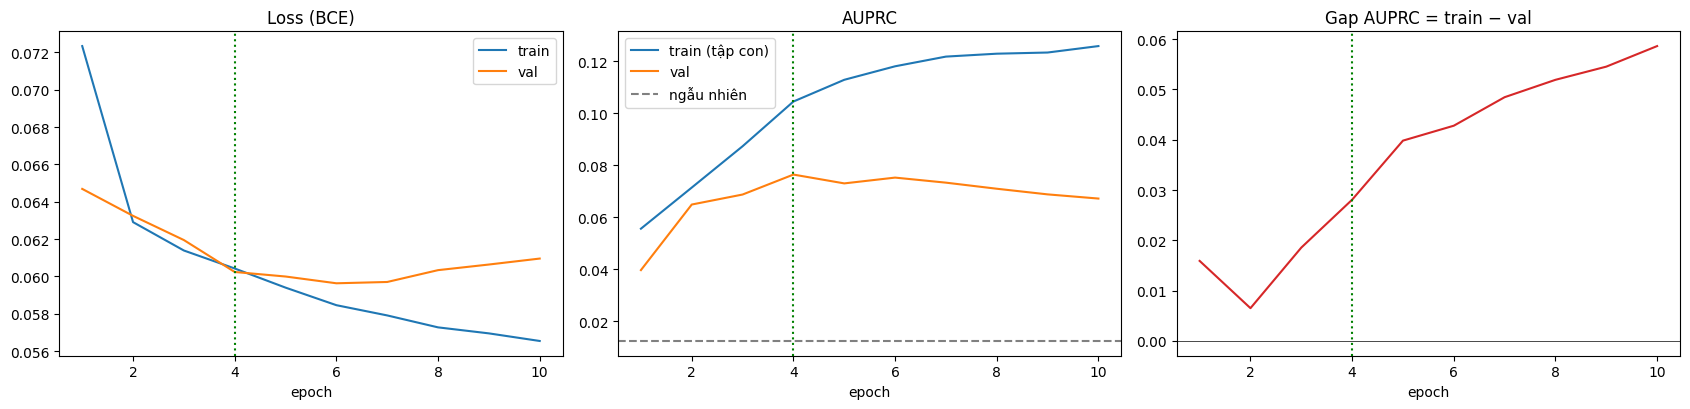

Tốt nhất: epoch 4 | val_auprc 0.076 | lift so với ngẫu nhiên 6.2x


In [6]:
H = pd.DataFrame(st["history"]); b = st["best_epoch"]
display(H.round(4).set_index("epoch"))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(H.epoch, H.loss, label="train"); ax[0].plot(H.epoch, H.val_loss, label="val"); ax[0].set_title("Loss (BCE)")
ax[1].plot(H.epoch, H.auprc, label="train (tập con)"); ax[1].plot(H.epoch, H.val_auprc, label="val")
ax[1].axhline(ytr.mean(), ls="--", c="gray", label="ngẫu nhiên"); ax[1].set_title("AUPRC")
ax[2].plot(H.epoch, H.gap, c="C3"); ax[2].axhline(0, c="k", lw=.5); ax[2].set_title("Gap AUPRC = train − val")
for a in ax: a.axvline(b, ls=":", c="g"); a.set_xlabel("epoch")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
print(f"Tốt nhất: epoch {b} | val_auprc {st['best']:.3f} | lift so với ngẫu nhiên {st['best'] / yva.mean():.1f}x")

## 6. Chấm điểm và so sánh trên val

### 6.1 Điểm dự đoán của model tốt nhất
Dùng `best.keras` (epoch tốt nhất theo val), đổi logit sang xác suất, lưu `.npy`. **Chưa chạm test.**

,AUPRC,AUPRC_CI,lift_vs_random,AUROC,prevalence,n_pos,n_patients,Brier,ECE
model,,,,,,,,,
lgbm,0.071,0.042-0.114,5.756,0.771,0.012,868,121,0.012,0.004
cnn,0.076,0.042-0.131,6.202,0.738,0.012,868,121,0.012,0.002
quy_tac,0.047,0.030-0.075,3.812,0.728,0.012,868,121,NaN,NaN
ens,0.085,0.050-0.137,6.898,0.760,0.012,868,121,0.012,0.002


thr  precision  recall  specificity     f1  accuracy  \
model   FA/giờ                                                            
lgbm    0.04     0.127      0.169   0.054        0.997  0.082     0.985   
        0.50     0.034      0.086   0.315        0.958  0.135     0.950   
        1.00     0.022      0.060   0.427        0.917  0.105     0.911   
        2.00     0.014      0.041   0.571        0.833  0.076     0.830   
cnn     0.04     0.143      0.225   0.077        0.997  0.115     0.985   
        0.50     0.050      0.076   0.276        0.958  0.120     0.950   
        1.00     0.032      0.052   0.364        0.917  0.090     0.910   
        2.00     0.019      0.036   0.497        0.833  0.067     0.829   
quy_tac 0.04   -74.000      0.101   0.028        0.997  0.043     0.985   
        0.50   -88.000      0.073   0.243        0.962  0.113     0.953   
        1.00   -90.000      0.064   0.380        0.931  0.110     0.924   
        2.00   -92.000      0.044   0.494        0.865  0.080     0.860   
ens     0.04     0.120      0.249   0.089        0.997  0.131     0.985   
        0.50     0.041      0.091   0.336        0.958  0.144     0.951   
        1.00     0.027      0.058   0.415        0.917  0.102     0.910   
        2.00     0.017      0.038   0.522        0.833  0.070     0.830   

                event_recall  FA_per_h  FA_per_day  
model   FA/giờ                                      
lgbm    0.04           0.162     0.040       0.955  
        0.50           0.494     0.500      11.996  
        1.00           0.656     1.000      23.997  
        2.00           0.788     2.000      47.998  
cnn     0.04           0.119     0.040       0.955  
        0.50           0.381     0.500      11.996  
        1.00           0.462     1.000      23.997  
        2.00           0.662     2.000      47.998  
quy_tac 0.04           0.075     0.037       0.881  
        0.50           0.506     0.459      11.012  
        1.00           0.631     0.829      19.891  
        2.00           0.731     1.624      38.967  
ens     0.04           0.156     0.040       0.959  
        0.50           0.481     0.500      11.996  
        1.00           0.575     1.000      23.997  
        2.00           0.725     2.000      47.998

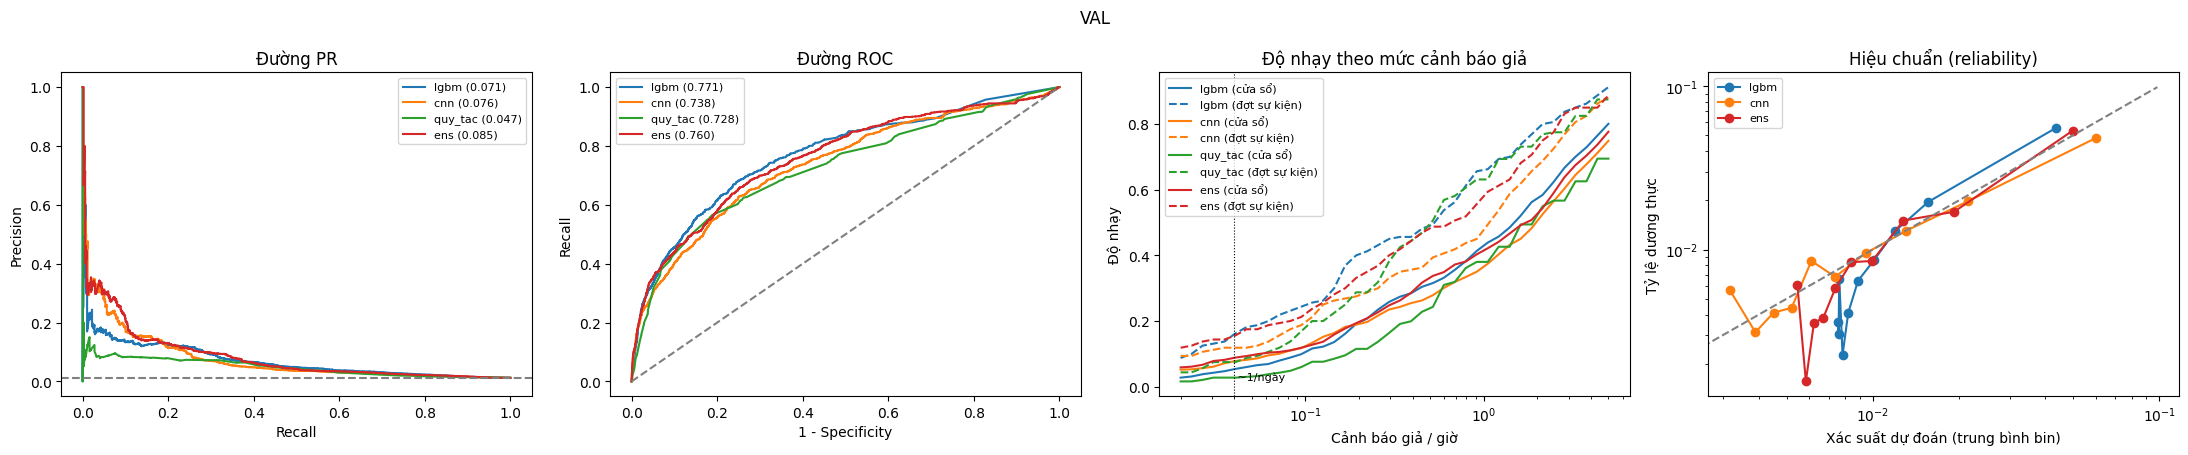

In [12]:
best = keras.models.load_model(P("best.keras"))
s_val = sig(best.predict(Xva, batch_size=4096, verbose=0).ravel()); np.save(P("scores_val.npy"), s_val)

import eval_utils as E
yv = yva.astype("int8"); isp = lambda n: n != "quy_tac"
ld = lambda k: np.load(f'{CFG["DATA_DIR"]}/{k}.npz')
MV = {c: ld("val")[c] for c in ("pid", "rec", "start")}
S_val = {"lgbm": np.load("runs/lgbm_val.npy"), "cnn": s_val, "quy_tac": np.load("runs/rule_val.npy")}
MODELS = list(S_val)
COL = {"lgbm": "C0", "cnn": "C1", "quy_tac": "C7"}    
S_val["ens"] = (S_val["lgbm"] + S_val["cnn"]) / 2      
MODELS = list(S_val); COL["ens"] = "C2"                

thr = {n: E.pick_thresholds(S_val[n], yv) for n in MODELS}
cv = [E.evaluate(n, S_val[n], yv, thr[n], MV, is_prob=isp(n)) for n in MODELS]
t1, t2 = E.report(cv); display(t1.round(3)); display(t2.round(3)); E.plot_curves(cv, "VAL")

## 7. Test (chạy MỘT lần)
Chỉ chạy khi đã chốt model, cấu hình và ngưỡng dựa trên val. Nếu đổi gì sau khi xem test thì kết quả không còn khách quan.
Gồm: chỉ số mức cửa sổ, và mô phỏng luồng cảnh báo (persistence, cooldown) giống notebook LightGBM.

,AUPRC,AUPRC_CI,lift_vs_random,AUROC,prevalence,n_pos,n_patients,Brier,ECE,Brier_isotonic,ECE_isotonic
model,,,,,,,,,,,
lgbm,0.084,0.049-0.114,6.533,0.812,0.013,917,119,0.012,0.006,0.012,0.003
cnn,0.062,0.035-0.088,4.827,0.778,0.013,917,119,0.012,0.002,0.012,0.002
quy_tac,0.050,0.035-0.066,3.928,0.775,0.013,917,119,NaN,NaN,NaN,NaN


thr  precision  recall  specificity     f1  accuracy  \
model   FA/giờ                                                            
lgbm    0.04     0.127      0.177   0.058        0.997  0.087     0.984   
        0.50     0.034      0.094   0.368        0.954  0.149     0.946   
        1.00     0.022      0.069   0.487        0.914  0.120     0.909   
        2.00     0.014      0.048   0.666        0.830  0.090     0.828   
cnn     0.04     0.143      0.107   0.038        0.996  0.056     0.984   
        0.50     0.050      0.078   0.320        0.951  0.125     0.943   
        1.00     0.032      0.057   0.465        0.901  0.102     0.895   
        2.00     0.019      0.040   0.641        0.803  0.076     0.801   
quy_tac 0.04   -74.000      0.064   0.015        0.997  0.025     0.985   
        0.50   -88.000      0.074   0.274        0.956  0.117     0.947   
        1.00   -90.000      0.066   0.441        0.919  0.115     0.913   
        2.00   -92.000      0.047   0.601        0.843  0.088     0.840   

                event_recall  FA_per_h  FA_per_day  
model   FA/giờ                                      
lgbm    0.04           0.167     0.042       1.006  
        0.50           0.649     0.553      13.275  
        1.00           0.750     1.029      24.708  
        2.00           0.851     2.038      48.907  
cnn     0.04           0.083     0.050       1.194  
        0.50           0.452     0.591      14.183  
        1.00           0.649     1.189      28.526  
        2.00           0.804     2.368      56.836  
quy_tac 0.04           0.048     0.035       0.835  
        0.50           0.589     0.531      12.753  
        1.00           0.720     0.968      23.237  
        2.00           0.815     1.885      45.240

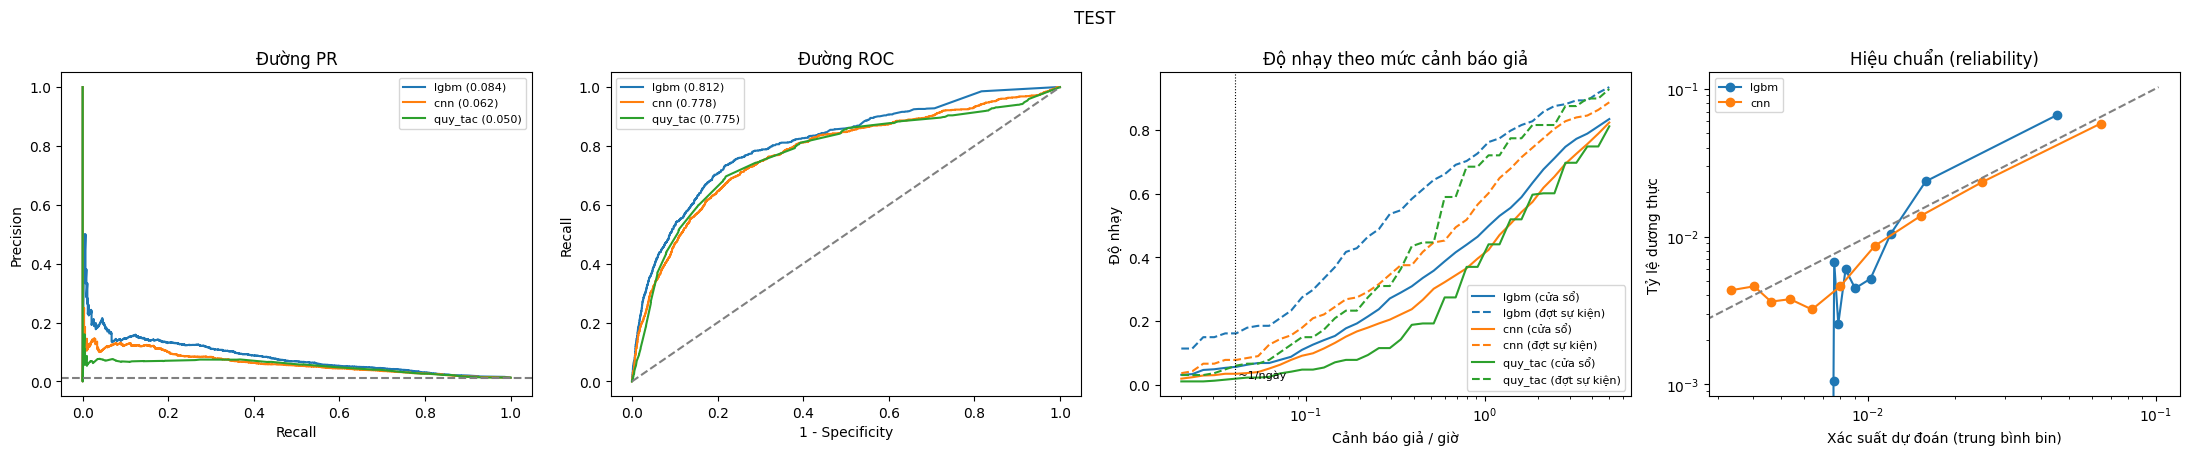

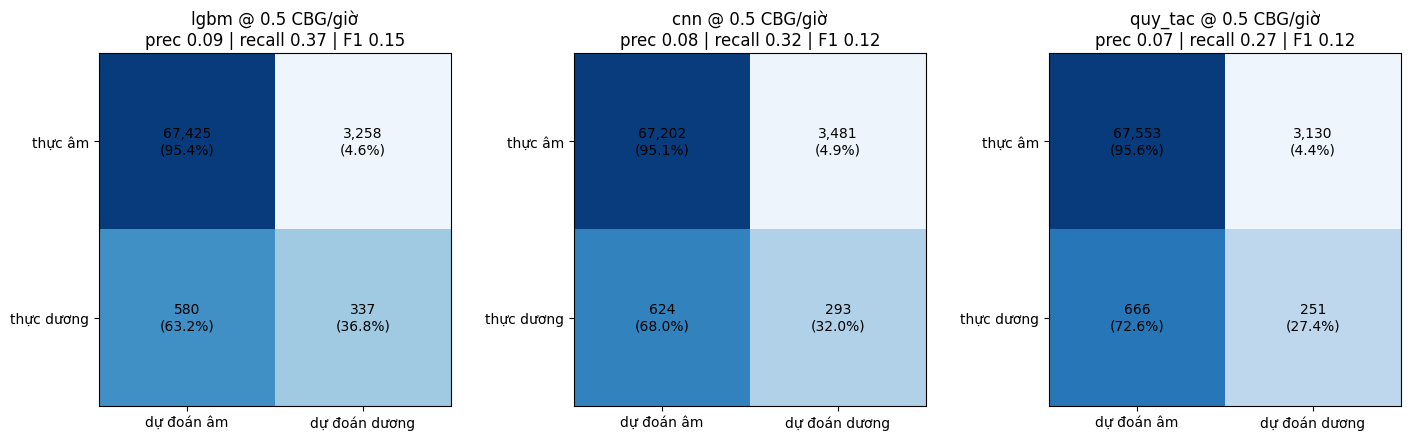

In [8]:
yt = yte.astype("int8"); MT = {c: ld("test")[c] for c in ("pid", "rec", "start")}
s_test = sig(best.predict(Xte, batch_size=4096, verbose=0).ravel()); np.save(P("scores_test.npy"), s_test)
S_test = {"lgbm": np.load("runs/lgbm_test.npy"), "cnn": s_test, "quy_tac": np.load("runs/rule_test.npy")}

ct = [E.evaluate(n, S_test[n], yt, thr[n], MT, s_val=S_val[n], y_val=yv, is_prob=isp(n)) for n in MODELS]
t1, t2 = E.report(ct); display(t1.round(3)); display(t2.round(3))
E.plot_curves(ct, "TEST"); E.plot_confusions(ct, fa=0.5)

Cấu hình tốt nhất của từng model (chọn trên val, ràng buộc ≤ 2 báo giả/ngày):


,fa_budget,k,n,cooldown
lgbm,0.2,1.0,1.0,30.0
cnn,0.2,1.0,1.0,30.0
quy_tac,0.2,1.0,1.0,30.0


Kết quả TEST (cấu hình ở trên áp lên test):


,lgbm,cnn,quy_tac
alerts_per_day,2.212,1.814,2.067
FA_per_day,1.919,1.613,1.895
precision,0.133,0.111,0.084
caught_any,0.413,0.280,0.257
caught_useful,0.307,0.211,0.211
missed,0.587,0.720,0.743
lead_med,11.000,10.000,11.500
lead_p25,4.250,5.000,6.750
FA_day_pt_med,1.051,0.453,1.051
FA_day_pt_p90,5.936,5.703,6.307


Tầng Critical (luật). Số thông báo/bệnh nhân/ngày, đã gộp sự kiện cách nhau <30 phút: {'alerts_per_day': np.float64(0.94), 'FA_day_pt_med': np.float64(0.19), 'FA_day_pt_p90': np.float64(2.92), 'FA_day_pt_max': np.float64(8.11), 'n_events': 262, 'patients': 111}


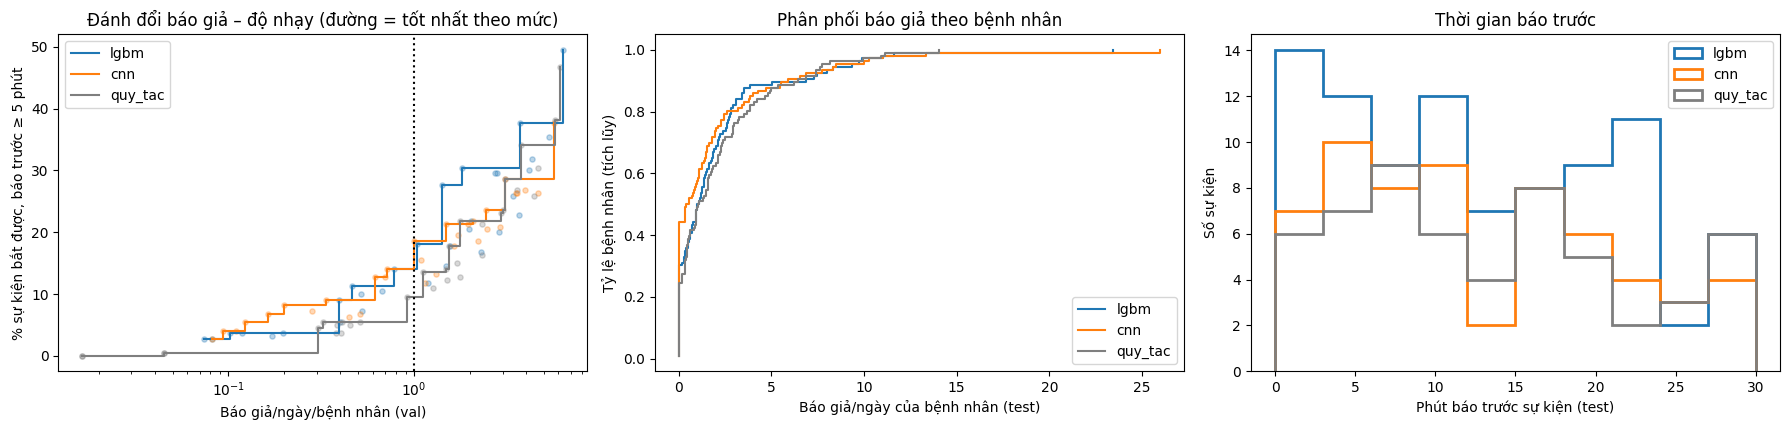

In [9]:
import sim_alert as SA
CLEAN_DIR = os.path.join(os.path.dirname(CFG["DATA_DIR"]), "clean_1min")
MAX_FA_DAY, MIN_H = 2, 12                      # ngân sách báo giả/ngày; MIN_H khớp min_hours trong sim_alert

tl_val  = {n: SA.build_timelines(S_val[n],  MV, CLEAN_DIR) for n in MODELS}
tl_test = {n: SA.build_timelines(S_test[n], MT, CLEAN_DIR) for n in MODELS}

THR_MAP, sw, best_cfg, res = {}, {}, {}, {}
for n in MODELS:
    THR_MAP[n] = E.pick_thresholds(S_val[n], yv, fa_levels=(0.04, 0.2, 0.5, 1))   # ngưỡng chọn trên val
    sw[n] = SA.sweep(tl_val[n], THR_MAP[n])                                       # quét cấu hình trên val
    cand = sw[n][sw[n]["FA_per_day"] <= MAX_FA_DAY].sort_values("caught_useful", ascending=False)
    assert len(cand), f"{n}: không cấu hình nào đạt {MAX_FA_DAY} báo giả/ngày, hãy tăng MAX_FA_DAY"
    best_cfg[n] = cand.iloc[0]; b = best_cfg[n]
    res[n] = SA.run_stream(tl_test[n], b["thr"], int(b["k"]), int(b["n"]), int(b["cooldown"]))   # áp lên test

rows = ["alerts_per_day", "FA_per_day", "precision", "caught_any", "caught_useful", "missed",
        "lead_med", "lead_p25", "FA_day_pt_med", "FA_day_pt_p90", "FA_day_pt_max", "top10pct_share"]
print("Cấu hình tốt nhất của từng model (chọn trên val, ràng buộc ≤ %g báo giả/ngày):" % MAX_FA_DAY)
display(pd.DataFrame({n: best_cfg[n][["fa_budget", "k", "n", "cooldown"]] for n in MODELS}).T)
print("Kết quả TEST (cấu hình ở trên áp lên test):")
display(pd.DataFrame({n: pd.Series(res[n][0]) for n in MODELS}).loc[rows].round(3))
crit = SA.critical_stats(tl_test[MODELS[0]])      # luật SpO2<88% ≥3 phút: không phụ thuộc model
print("Tầng Critical (luật). Số thông báo/bệnh nhân/ngày, đã gộp sự kiện cách nhau <30 phút:", {k: round(v, 2) for k, v in crit.items()})

# --- Đồ thị chồng nhiều model: cùng trục, cùng màu ---
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
for n in MODELS:
    x, y = sw[n]["FA_per_day"].to_numpy(), sw[n]["caught_useful"].to_numpy() * 100; o = np.argsort(x)
    ax[0].scatter(x, y, s=14, alpha=.3, c=COL[n]); ax[0].step(x[o], np.maximum.accumulate(y[o]), where="post", c=COL[n], label=n)
    pt = res[n][1]; fa = np.sort(pt.loc[pt["hours"] >= MIN_H, "fa_per_day"].to_numpy(float))   # báo giả/NGÀY của từng bệnh nhân
    ax[1].step(fa, np.arange(1, len(fa) + 1) / len(fa), where="post", c=COL[n], label=n)
    ax[2].hist(np.asarray(res[n][2], float), bins=np.arange(0, 33, 3), histtype="step", lw=2, color=COL[n], label=n)
ax[0].set_xscale("log"); ax[0].axvline(1, ls=":", c="k")
ax[0].set(xlabel="Báo giả/ngày/bệnh nhân (val)", ylabel="% sự kiện bắt được, báo trước ≥ 5 phút", title="Đánh đổi báo giả – độ nhạy (đường = tốt nhất theo mức)")
ax[1].set(xlabel="Báo giả/ngày của bệnh nhân (test)", ylabel="Tỷ lệ bệnh nhân (tích lũy)", title="Phân phối báo giả theo bệnh nhân")
ax[2].set(xlabel="Phút báo trước sự kiện (test)", ylabel="Số sự kiện", title="Thời gian báo trước")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

TEST | cùng cấu hình: {'fa_budget': 0.2, 'k': 1, 'n': 1, 'cooldown': 60}


,lgbm,cnn,quy_tac
alerts_per_day,1.689,1.263,1.758
FA_per_day,1.452,1.102,1.605
precision,0.140,0.127,0.087
caught_any,0.335,0.229,0.229
caught_useful,0.243,0.179,0.183
missed,0.665,0.771,0.771
lead_med,11.000,11.000,11.500
lead_p25,4.000,5.250,7.000
FA_day_pt_med,0.963,0.353,0.996
FA_day_pt_p90,3.147,3.877,4.787


[lgbm] Watch = (1,1,30) @0.5 báo giả/giờ | Alert = (1,1,30) @0.2 báo giả/giờ


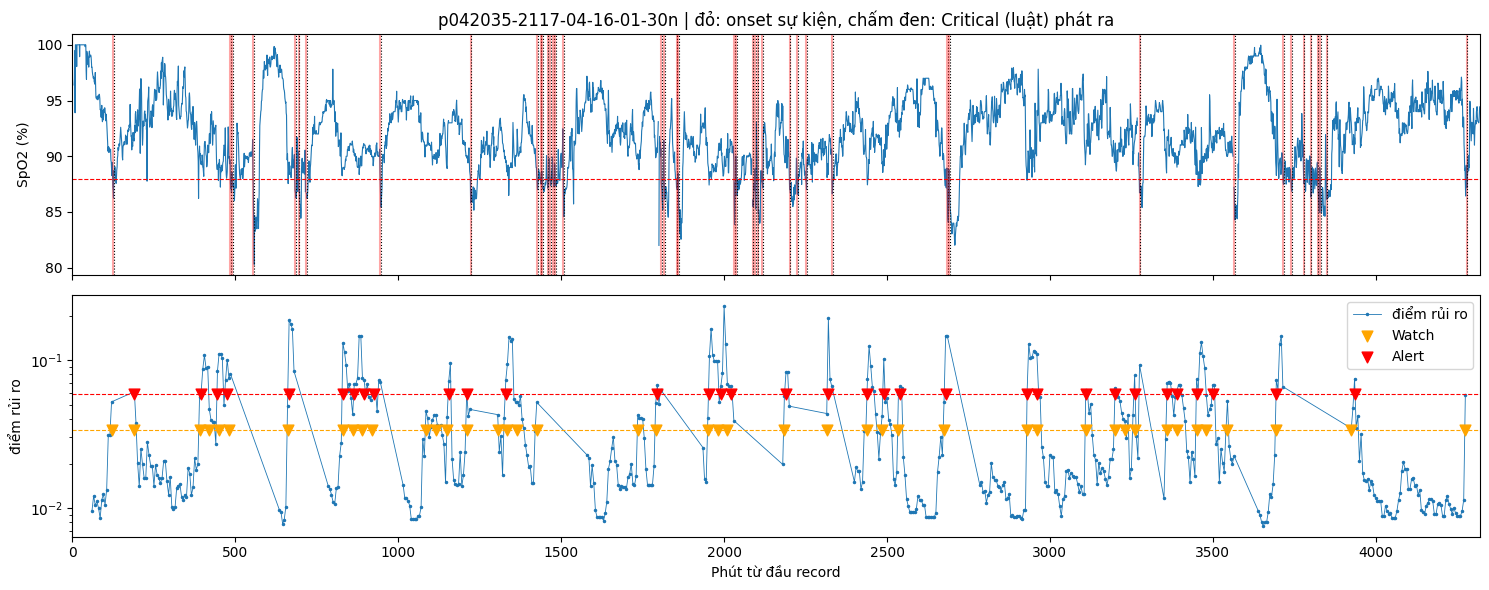

[cnn] Watch = (1,1,30) @0.5 báo giả/giờ | Alert = (1,1,30) @0.2 báo giả/giờ


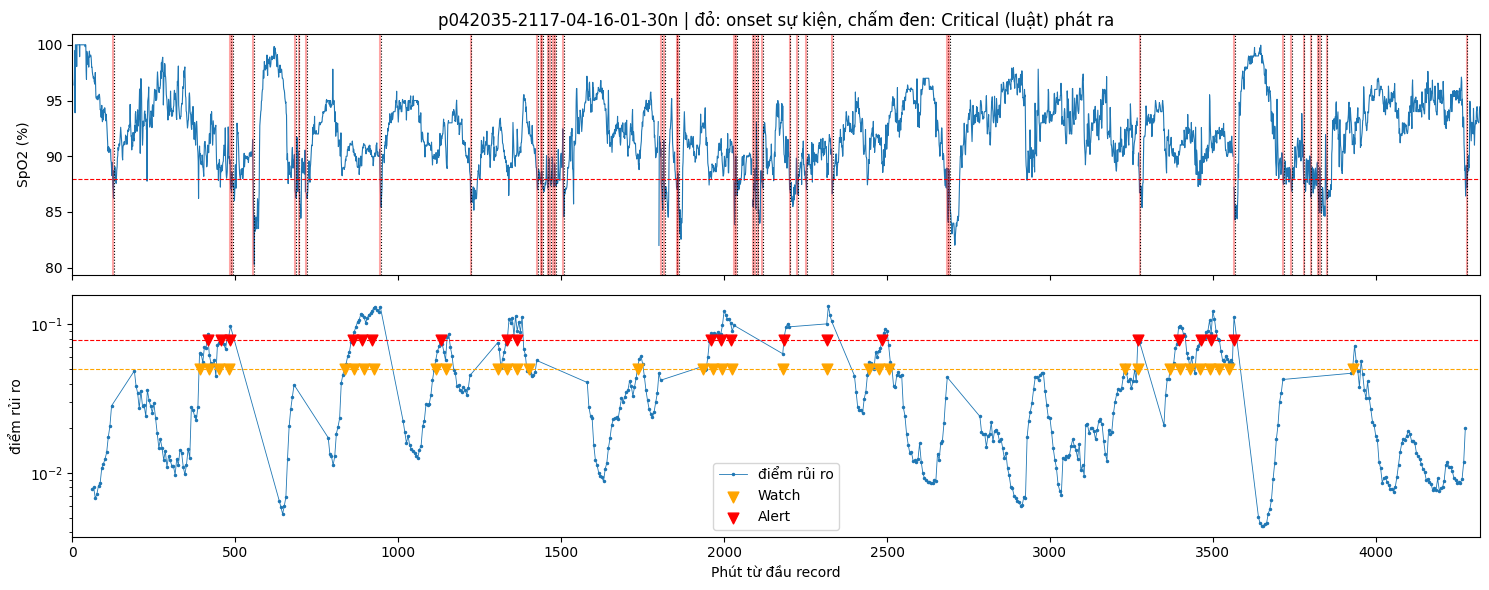

In [10]:
# --- So sánh CÙNG cấu hình (tách chất lượng model khỏi việc mỗi model tự chọn cấu hình) ---
FIX = dict(fa_budget=0.2, k=1, n=1, cooldown=60)          # đổi tùy ý; áp cho mọi model
fx = {n: SA.run_stream(tl_test[n], THR_MAP[n][FIX["fa_budget"]], FIX["k"], FIX["n"], FIX["cooldown"])[0] for n in MODELS}
print("TEST | cùng cấu hình:", FIX)
display(pd.DataFrame({n: pd.Series(fx[n]) for n in MODELS}).loc[rows].round(3))

# --- Vẽ CÙNG một record cho các model, dùng đúng cấu hình đã đánh giá (không dùng mặc định của plot_example) ---
t0 = tl_test[MODELS[0]]
rec0 = max(t0, key=lambda r: len(t0[r]["onsets"]) if len(t0[r]["t"]) > 50 else -1)      # record nhiều sự kiện nhất
for n in ("lgbm", "cnn"):
    b = best_cfg[n]
    print(f"[{n}] Watch = (1,1,30) @0.5 báo giả/giờ | Alert = ({int(b['k'])},{int(b['n'])},{int(b['cooldown'])}) @{b['fa_budget']} báo giả/giờ")
    SA.plot_example(tl_test[n], THR_MAP[n][0.5], b["thr"], cfg_watch=(1, 1, 30),
                    cfg_alert=(int(b["k"]), int(b["n"]), int(b["cooldown"])), rec=rec0)

## 8. Xuất model

### 8.1 Các định dạng
- `.keras`: model Keras đầy đủ (nạp lại để suy luận/fine-tune).
- SavedModel (`.export`): định dạng TensorFlow "thư mục `.tf`".
- `.tflite` INT8: bản cho ESP32 (TFLite Micro). Đầu ra là **logit đã lượng tử hóa**, firmware giải lượng tử (`(q − zero_point) × scale`) rồi áp sigmoid.
- `norm.npz` (`mu`, `sd`): firmware phải chuẩn hóa y hệt `prep()`: `(x − mu)/sd`, NaN → 0, thêm 2 kênh mask.

### 8.2 Kiểm tra lượng tử hóa
So AUPRC bản float và bản INT8 trên val. Chênh nhiều nghĩa là lượng tử hóa làm mất chất lượng.

In [11]:
EXPORT = "models"; os.makedirs(EXPORT, exist_ok=True)
best.save(f"{EXPORT}/cnn_thr88.keras"); best.export(f"{EXPORT}/cnn_thr88_savedmodel")
np.savez(f"{EXPORT}/cnn_thr88_norm.npz", mu=mu, sd=sd)

rng = np.random.default_rng(0)
rep = np.r_[rng.choice(len(Xtr), 800, replace=False), np.where(ytr == 1)[0][:200]]   # dữ liệu đại diện, có cả mẫu dương
conv = tf.lite.TFLiteConverter.from_keras_model(best)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = lambda: ([Xtr[i:i + 1]] for i in rep)                  # phải trả về LIST các mảng
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = conv.inference_output_type = tf.int8
open(f"{EXPORT}/cnn_thr88_int8.tflite", "wb").write(conv.convert())
print(f"TFLite INT8: {os.path.getsize(f'{EXPORT}/cnn_thr88_int8.tflite') / 1024:.1f} KB")

it = tf.lite.Interpreter(model_path=f"{EXPORT}/cnn_thr88_int8.tflite"); it.allocate_tensors()
a, o = it.get_input_details()[0], it.get_output_details()[0]
(sc, zp), (osc, ozp) = a["quantization"], o["quantization"]
def tflite_prob(X):
    out = np.empty(len(X), np.float32)
    for i, x in enumerate(X):
        it.set_tensor(a["index"], np.clip(np.round(x / sc + zp), -128, 127).astype(np.int8)[None]); it.invoke()
        out[i] = (it.get_tensor(o["index"])[0, 0].astype(np.float32) - ozp) * osc
    return sig(out)
p8 = tflite_prob(Xva)
print(f"AUPRC val | float {average_precision_score(yva, s_val):.4f} | INT8 {average_precision_score(yva, p8):.4f}")

INFO:tensorflow:Assets written to: models/cnn_thr88_savedmodel\assets


INFO:tensorflow:Assets written to: models/cnn_thr88_savedmodel\assets


Saved artifact at 'models/cnn_thr88_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 60, 6), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2677971626016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971630944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971799904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971804832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971809584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971810288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971848000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971848704: TensorSpec(shape=(), dtype=tf.resource, name=None)
INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmpw1zk90ve\assets


INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmpw1zk90ve\assets


Saved artifact at 'C:\Users\LENOVO\AppData\Local\Temp\tmpw1zk90ve'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 60, 6), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2677971626016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971630944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971799904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971804832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971809584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971810288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971848000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2677971848704: TensorSpec(shape=(), dtype=tf.resource, name=None)


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\.venv\lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite INT8: 15.1 KB


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\.venv\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


AUPRC val | float 0.0763 | INT8 0.0754


## 9. Thí nghiệm cải thiện học sâu

In [13]:
def take(X, idx): return {k: v[idx] for k, v in X.items()} if isinstance(X, dict) else X[idx]
def nrows(X): return len(next(iter(X.values()))) if isinstance(X, dict) else len(X)

class Run(keras.callbacks.Callback):
    def __init__(self, run, st, Xv, yv, Xs, ys, max_epochs, patience):
        super().__init__(); self.run, self.st, self.Xv, self.yv, self.Xs, self.ys = run, st, Xv, yv, Xs, ys
        self.E, self.pat = max_epochs, patience
    def _save(self, path): tmp = path + ".tmp.keras"; self.model.save(tmp); os.replace(tmp, path)
    def _prob(self, X): return sig(self.model.predict(X, batch_size=4096, verbose=0).ravel())
    def on_train_begin(self, logs=None):
        self.outer = tqdm(total=self.E, initial=self.st["epoch"], desc=self.run, unit="epoch", position=0)
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time(); self.inner = tqdm(total=self.params["steps"], desc=f"Epoch {epoch+1}/{self.E}", leave=False, position=1)
    def on_train_batch_end(self, batch, logs=None): self.inner.update(1)
    def on_epoch_end(self, epoch, logs=None):
        self.inner.close(); st = self.st; pv, ps = self._prob(self.Xv), self._prob(self.Xs)
        r = dict(epoch=epoch + 1, loss=logs["loss"], val_loss=logs["val_loss"], auprc=average_precision_score(self.ys, ps),
                 val_auprc=average_precision_score(self.yv, pv), val_auroc=roc_auc_score(self.yv, pv), sec=time.time() - self.t0)
        r["gap"] = r["auprc"] - r["val_auprc"]; st["history"].append(r); note = ""
        if r["val_auprc"] > st["best"]:
            st["best"], st["best_epoch"], st["wait"] = r["val_auprc"], r["epoch"], 0; self._save(f"{self.run}/best.keras"); note = "★"
        else: st["wait"] += 1
        st["epoch"] = r["epoch"]; st["done"] = st["wait"] >= self.pat or r["epoch"] >= self.E
        self._save(f"{self.run}/last.keras")
        json.dump(st, open(f"{self.run}/state.json.tmp", "w")); os.replace(f"{self.run}/state.json.tmp", f"{self.run}/state.json")
        self.outer.update(1)
        self.outer.write(f"{r['epoch']:>3} | loss {r['loss']:.4f} val {r['val_loss']:.4f} | auprc {r['auprc']:.3f} val {r['val_auprc']:.3f} "
                         f"auroc {r['val_auroc']:.3f} | gap {r['gap']:.3f} | {r['sec']:.0f}s {note}")
        if st["done"]: self.model.stop_training = True
    def on_train_end(self, logs=None): self.outer.close()

def train_run(name, build, Xtr, ytr, Xva, yva, seed, lr=1e-3, batch=512, max_epochs=40, patience=6, pos_weight=1.0, root="runs"):
    run = f"{root}/{name}_s{seed}"; os.makedirs(run, exist_ok=True); pth = lambda f: f"{run}/{f}"
    keras.utils.set_random_seed(seed)
    if os.path.exists(pth("state.json")) and os.path.exists(pth("last.keras")):
        st = json.load(open(pth("state.json"))); model = keras.models.load_model(pth("last.keras"))
    else:
        st = dict(epoch=0, best=-1.0, best_epoch=-1, wait=0, done=False, history=[]); model = build(lr)
    if st["done"]:
        print(f"✔ {run}: đã xong (val_auprc tốt nhất {st['best']:.3f} ở epoch {st['best_epoch']})"); return run
    sub = np.random.default_rng(1).choice(nrows(Xtr), min(70000, nrows(Xtr)), replace=False)
    model.fit(Xtr, ytr, validation_data=(Xva, yva), batch_size=batch, epochs=max_epochs, initial_epoch=st["epoch"],
              class_weight=None if pos_weight == 1 else {0: 1.0, 1: pos_weight},
              callbacks=[Run(run, st, Xva, yva, take(Xtr, sub), ytr[sub], max_epochs, patience)], verbose=0)
    return run

In [14]:
@keras.utils.register_keras_serializable(package="spo2")
class Augment(keras.layers.Layer):
    """Chỉ hoạt động khi train; khi suy luận/xuất TFLite là phép đồng nhất.
    Kênh: 0 spo2_mean, 1 spo2_min, 2 spo2_valid, 3 pulse_mean, 4-5 mask. Đơn vị là z-score
    (kiểm tra `sd[0]`: nếu sd SpO2 ≈ 4% thì shift_sd=0.25 ≈ lệch 1%)."""
    def __init__(self, shift_sd=0.25, noise_sd=0.05, drop_p=0.03, **kw):
        super().__init__(**kw); self.shift_sd, self.noise_sd, self.drop_p = shift_sd, noise_sd, drop_p
    def call(self, x, training=None):
        if not training: return x
        n, T = tf.shape(x)[0], tf.shape(x)[1]
        val = tf.constant([1., 1., 0., 1., 0., 0.]); spo2 = tf.constant([1., 1., 0., 0., 0., 0.])
        x = x + tf.random.normal([n, 1, 1], 0.0, self.shift_sd) * spo2            # lệch nền SpO2 (sai số cảm biến)
        x = x + tf.random.normal(tf.shape(x), 0.0, self.noise_sd) * val             # nhiễu nhỏ
        drop = tf.cast(tf.random.uniform([n, T, 1]) < self.drop_p, x.dtype)         # rớt ngẫu nhiên vài phút (nhiễu chuyển động)
        x = x * (1 - drop * val); return x + drop * tf.constant([0., 0., 0., 0., 1., 1.])
    def get_config(self): return {**super().get_config(), "shift_sd": self.shift_sd, "noise_sd": self.noise_sd, "drop_p": self.drop_p}

def _compile(m, lr): m.compile(keras.optimizers.Adam(lr), keras.losses.BinaryCrossentropy(from_logits=True)); return m
def _conv(x, filters=(16, 32, 32), kernel=5):
    L = keras.layers
    for i, f in enumerate(filters):
        x = L.Conv1D(f, kernel if i < 2 else 3, padding="same", activation="relu")(x)
        if i < 2: x = L.MaxPooling1D(2)(x)
    return L.GlobalAveragePooling1D()(x)

def build_cnn(lr=1e-3, aug=False, dropout=0.2, filters=(16, 32, 32)):
    L = keras.layers; inp = keras.Input((60, 6), name="seq"); x = Augment()(inp) if aug else inp
    return _compile(keras.Model(inp, L.Dense(1)(L.Dropout(dropout)(_conv(x, filters)))), lr)

def build_hybrid(lr=1e-3, aug=False, dropout=0.2, filters=(16, 32, 32), n_tab=20, tab_units=32):
    L = keras.layers; s = keras.Input((60, 6), name="seq"); t = keras.Input((n_tab,), name="tab")
    z = L.Concatenate()([_conv(Augment()(s) if aug else s, filters), L.Dense(tab_units, activation="relu")(t)])
    z = L.Dense(16, activation="relu")(L.Dropout(dropout)(z))
    return _compile(keras.Model([s, t], L.Dense(1)(z)), lr)

In [15]:
TAB = ["sp_mean", "sp_med", "sp_p10", "mn_min60", "frac_lt95", "frac_lt92", "frac_lt90", "pu_mean",
       "sp_slope60", "sp_slope30", "sp_d_last10_first30", "sp_std60", "sp_std15", "pu_slope30", "pu_d_last10_first30", "pu_std60",
       "mn_min10", "sp_last5", "valid_mean", "sp_nan_frac"]
FEAT_DIR = os.path.join(os.path.dirname(CFG["DATA_DIR"]), "features_thr88")
Ftab = {k: pd.read_parquet(f"{FEAT_DIR}/{k}.parquet") for k in ("train", "val", "test")}
for k, y_ in (("train", ytr), ("val", yva), ("test", yte)):
    assert (Ftab[k]["y"].to_numpy() == y_).all(), f"{k}: thứ tự hàng của đặc trưng không khớp npz"
med = Ftab["train"][TAB].median()
_imp = Ftab["train"][TAB].fillna(med); tmu, tsd = _imp.mean(), _imp.std() + 1e-6
np.savez(P("tab_norm.npz"), med=med.to_numpy(), mu=tmu.to_numpy(), sd=tsd.to_numpy(), cols=np.array(TAB))
tab = lambda k: ((Ftab[k][TAB].fillna(med) - tmu) / tsd).clip(-5, 5).to_numpy("float32")
Xtr_h, Xva_h, Xte_h = ({"seq": s, "tab": tab(k)} for s, k in ((Xtr, "train"), (Xva, "val"), (Xte, "test")))

In [16]:
SEEDS = (1, 2, 3)
EXP = {   
    "cnn":        (build_cnn, "seq"),
    "cnn_aug":    (lambda lr: build_cnn(lr, aug=True), "seq"),
    "hybrid":     (build_hybrid, "hyb"),
    "hybrid_aug": (lambda lr: build_hybrid(lr, aug=True), "hyb"),
}
RUN_NOW = ["hybrid", "cnn_aug"]           
DATA = {"seq": (Xtr, Xva, Xte), "hyb": (Xtr_h, Xva_h, Xte_h)}
for nm in RUN_NOW:
    b, dk = EXP[nm]
    for s in SEEDS: train_run(nm, b, DATA[dk][0], ytr, DATA[dk][1], yva, s)

runs/hybrid_s1:   2%|▎         | 1/40 [00:17<11:13, 17.26s/epoch]

  1 | loss 0.0693 val 0.0603 | auprc 0.096 val 0.058 auroc 0.762 | gap 0.038 | 17s ★


runs/hybrid_s1:   5%|▌         | 2/40 [00:28<08:34, 13.54s/epoch]

  2 | loss 0.0577 val 0.0598 | auprc 0.102 val 0.060 auroc 0.772 | gap 0.042 | 11s ★


runs/hybrid_s1:   8%|▊         | 3/40 [00:50<10:42, 17.37s/epoch]

...

 11 | loss 0.0585 val 0.0605 | auprc 0.114 val 0.060 auroc 0.762 | gap 0.054 | 10s 


runs/cnn_aug_s3:  30%|███       | 12/40 [02:03<04:49, 10.33s/epoch]

 12 | loss 0.0582 val 0.0609 | auprc 0.117 val 0.055 auroc 0.759 | gap 0.062 | 11s 


runs/cnn_aug_s3:  32%|███▎      | 13/40 [02:15<04:41, 10.43s/epoch]

 13 | loss 0.0579 val 0.0609 | auprc 0.122 val 0.057 auroc 0.755 | gap 0.065 | 12s 


In [17]:
import eval_utils as E
yv = yva.astype("int8"); zv = np.load(f'{CFG["DATA_DIR"]}/val.npz'); MV = {c: zv[c] for c in ("pid", "rec", "start")}
def val_score(run, dk):
    m = keras.models.load_model(f"{run}/best.keras"); return sig(m.predict(DATA[dk][1], batch_size=4096, verbose=0).ravel())
def card(name, s):
    c = E.evaluate(name, s, yv, E.pick_thresholds(s, yv), MV, n_boot=20); o = c["ops"]
    return dict(model=name, AUPRC=c["summary"]["AUPRC"], AUROC=c["summary"]["AUROC"], **{f"ev@{fa}": o[fa]["event_recall"] for fa in (0.04, 0.5, 1)})
rows, S_exp = [], {}
for nm in RUN_NOW:
    dk = EXP[nm][1]; S = [val_score(f"runs/{nm}_s{s}", dk) for s in SEEDS]
    rows += [card(f"{nm}_s{s}", sc) for s, sc in zip(SEEDS, S)]
    S_exp[nm + "_ens"] = np.mean(S, 0); rows.append(card(nm + "_ens", S_exp[nm + "_ens"]))
rows.append(card("lgbm", S_val["lgbm"])); rows.append(card("cnn_goc (1 seed)", S_val["cnn"]))
T = pd.DataFrame(rows).set_index("model"); display(T.round(3))
seed_rows = T[T.index.str.contains(r"_s\d$")].copy(); seed_rows["exp"] = seed_rows.index.str.rsplit("_s", n=1).str[0]
print("Trung bình ± độ lệch giữa các seed (ev@x = độ nhạy mức sự kiện tại x báo giả/giờ):")
display(seed_rows.groupby("exp")[["AUPRC", "AUROC", "ev@0.04", "ev@0.5", "ev@1"]].agg(["mean", "std"]).round(3))

,AUPRC,AUROC,ev@0.04,ev@0.5,ev@1
model,,,,,
hybrid_s1,0.067,0.778,0.125,0.562,0.638
hybrid_s2,0.068,0.768,0.112,0.531,0.638
hybrid_s3,0.065,0.772,0.125,0.575,0.669
hybrid_ens,0.069,0.778,0.112,0.538,0.638
cnn_aug_s1,0.064,0.739,0.112,0.456,0.638
cnn_aug_s2,0.059,0.738,0.069,0.312,0.469
cnn_aug_s3,0.066,0.757,0.088,0.412,0.631
cnn_aug_ens,0.065,0.755,0.094,0.381,0.619
lgbm,0.071,0.771,0.162,0.494,0.656


Trung bình ± độ lệch giữa các seed (ev@x = độ nhạy mức sự kiện tại x báo giả/giờ):


AUPRC         AUROC        ev@0.04        ev@0.5          ev@1       
          mean    std   mean    std    mean    std   mean    std   mean    std
exp                                                                           
cnn_aug  0.063  0.003  0.745  0.011   0.090  0.022  0.394  0.074  0.579  0.096
hybrid   0.067  0.001  0.773  0.005   0.121  0.007  0.556  0.023  0.648  0.018

,AUPRC,AUROC,ev@0.04,ev@0.5,ev@1,FA/h thực@0.5,FA/h thực@1
model,,,,,,,
hybrid_s1,0.074,0.804,0.143,0.625,0.762,0.567,1.088
hybrid_s2,0.077,0.801,0.161,0.625,0.750,0.555,1.051
hybrid_s3,0.072,0.808,0.131,0.649,0.786,0.530,1.047
hybrid_ens,0.076,0.806,0.137,0.619,0.762,0.555,1.071
lgbm,0.084,0.812,0.167,0.649,0.750,0.553,1.029


Họ hybrid, trung bình ± độ lệch giữa 3 seed (TEST):


,AUPRC,AUROC,ev@0.04,ev@0.5,ev@1,FA/h thực@0.5,FA/h thực@1
mean,0.074,0.804,0.145,0.633,0.766,0.550,1.062
std,0.003,0.004,0.015,0.014,0.018,0.019,0.022


,AUPRC,AUPRC_CI,lift_vs_random,AUROC,prevalence,n_pos,n_patients,Brier,ECE,Brier_isotonic,ECE_isotonic
model,,,,,,,,,,,
hybrid_ens,0.076,0.047-0.104,5.906,0.806,0.013,917,119,0.012,0.004,0.012,0.002
lgbm,0.084,0.049-0.114,6.533,0.812,0.013,917,119,0.012,0.006,0.012,0.003


thr  precision  recall  specificity     f1  accuracy  \
model      FA/giờ                                                           
hybrid_ens 0.04    0.221      0.137   0.044        0.996  0.066     0.984   
           0.50    0.068      0.091   0.356        0.954  0.145     0.946   
           1.00    0.037      0.071   0.523        0.911  0.125     0.906   
           2.00    0.019      0.047   0.675        0.823  0.088     0.821   
lgbm       0.04    0.127      0.177   0.058        0.997  0.087     0.984   
           0.50    0.034      0.094   0.368        0.954  0.149     0.946   
           1.00    0.022      0.069   0.487        0.914  0.120     0.909   
           2.00    0.014      0.048   0.666        0.830  0.090     0.828   

                   event_recall  FA_per_h  FA_per_day  
model      FA/giờ                                      
hybrid_ens 0.04           0.137     0.043       1.031  
           0.50           0.619     0.555      13.320  
           1.00           0.762     1.071      25.698  
           2.00           0.869     2.121      50.895  
lgbm       0.04           0.167     0.042       1.006  
           0.50           0.649     0.553      13.275  
           1.00           0.750     1.029      24.708  
           2.00           0.851     2.038      48.907

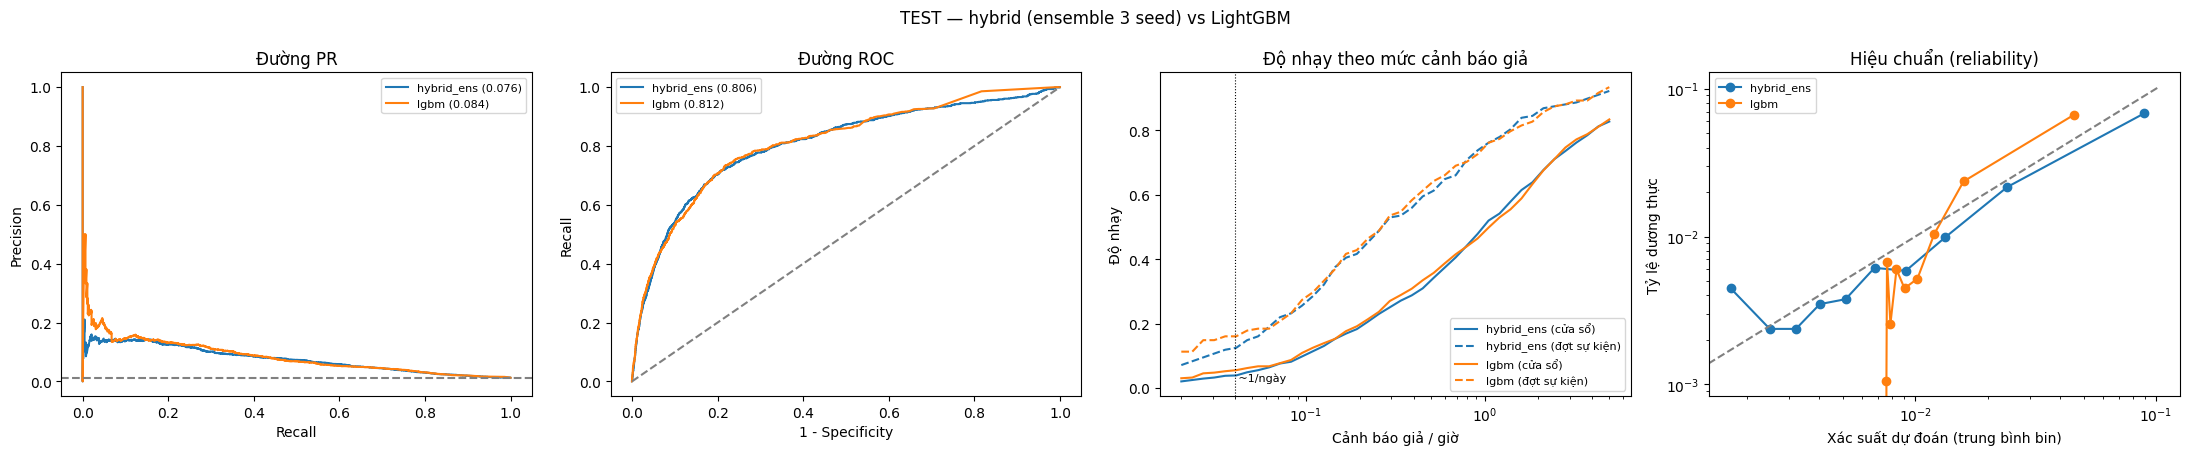

TEST | mức cảnh báo, cùng cấu hình: {'fa_budget': 0.2, 'k': 1, 'n': 1, 'cooldown': 60}


,hybrid_ens,lgbm
alerts_per_day,1.673,1.689
FA_per_day,1.416,1.452
precision,0.154,0.140
caught_any,0.353,0.335
caught_useful,0.261,0.243
missed,0.647,0.665
lead_med,11.000,11.000
FA_day_pt_p90,3.671,3.147
top10pct_share,0.445,0.461


In [18]:
import sim_alert as SA
FAM = "hybrid"; dk = EXP[FAM][1]
yt = yte.astype("int8"); zt = np.load(f'{CFG["DATA_DIR"]}/test.npz'); MT = {c: zt[c] for c in ("pid", "rec", "start")}
def test_score(run): m = keras.models.load_model(f"{run}/best.keras"); return sig(m.predict(DATA[dk][2], batch_size=4096, verbose=0).ravel())
names = [f"{FAM}_s{s}" for s in SEEDS]
Sv = {n: val_score(f"runs/{n}", dk) for n in names}; St = {n: test_score(f"runs/{n}") for n in names}
Sv[FAM + "_ens"], St[FAM + "_ens"] = np.mean([Sv[n] for n in names], 0), np.mean([St[n] for n in names], 0)
Sv["lgbm"], St["lgbm"] = S_val["lgbm"], S_test["lgbm"]

def card_t(n):                       # ngưỡng chọn trên VAL, áp lên TEST
    c = E.evaluate(n, St[n], yt, E.pick_thresholds(Sv[n], yv), MT, n_boot=20); o = c["ops"]
    return dict(model=n, AUPRC=c["summary"]["AUPRC"], AUROC=c["summary"]["AUROC"], **{f"ev@{fa}": o[fa]["event_recall"] for fa in (0.04, 0.5, 1)},
                **{f"FA/h thực@{fa}": o[fa]["FA_per_h"] for fa in (0.5, 1)})
TT = pd.DataFrame([card_t(n) for n in St]).set_index("model"); display(TT.round(3))
sr = TT.loc[names]; print("Họ hybrid, trung bình ± độ lệch giữa 3 seed (TEST):"); display(sr.agg(["mean", "std"]).round(3))

cts = [E.evaluate(n, St[n], yt, E.pick_thresholds(Sv[n], yv), MT, s_val=Sv[n], y_val=yv) for n in (FAM + "_ens", "lgbm")]
t1, t2 = E.report(cts); display(t1.round(3)); display(t2.round(3)); E.plot_curves(cts, "TEST — hybrid (ensemble 3 seed) vs LightGBM")

# --- mức cảnh báo, cùng cấu hình với bảng so sánh trước ---
CLEAN_DIR = os.path.join(os.path.dirname(CFG["DATA_DIR"]), "clean_1min"); FIX = dict(fa_budget=0.2, k=1, n=1, cooldown=60)
RA = ["alerts_per_day", "FA_per_day", "precision", "caught_any", "caught_useful", "missed", "lead_med", "FA_day_pt_p90", "top10pct_share"]
def alert_row(n):
    tl = SA.build_timelines(St[n], MT, CLEAN_DIR); thr = E.pick_thresholds(Sv[n], yv, fa_levels=(FIX["fa_budget"],))[FIX["fa_budget"]]
    return pd.Series(SA.run_stream(tl, thr, FIX["k"], FIX["n"], FIX["cooldown"])[0])
print("TEST | mức cảnh báo, cùng cấu hình:", FIX)
display(pd.DataFrame({n: alert_row(n) for n in (FAM + "_ens", "lgbm")}).loc[RA].round(3))